In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from matplotlib import colormaps
from matplotlib.patches import CirclePolygon
import matplotlib as mpl
import os
import glob 
from copy import deepcopy

In [2]:
indir = '/data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/'

# inputs = { 
#     "ttHH_dilep": "MGPy8EG_A14NNPDF23LO_ttHH_dilep", 
#     "ttHH_fullhad": "MGPy8EG_A14NNPDF23LO_ttHH_fullhad", 
#     "ttHH_semilep": "MGPy8EG_A14NNPDF23LO_ttHH_semilep", 
#     "ttbb": "PhPy8_A14_NNPDF31_ttbb_4FS_bzd5_dilep_shower", 
#     "ttbar_allhad": "PhPy8EG_A14_ttbar_hdamp258p75_allhad", 
#     "ttbar_dilep": "PhPy8EG_A14_ttbar_hdamp258p75_dil",
#     "ttbar_nonallhad": "PhPy8EG_A14_ttbar_hdamp258p75_nonallhad",
#     "QCD_JZ3": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ3WithSW",
#     "QCD_JZ4": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ4WithSW",
#     "QCD_JZ5": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ5WithSW",
#     "QCD_JZ6": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ6WithSW",
#     "QCD_JZ7": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ7WithSW",
#     "QCD_JZ8": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ8WithSW",
#     "QCD_JZ9": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ9WithSW",
#     "QCD_JZ10": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ10WithSW",
#     "QCD_JZ11": "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ11WithSW",
# }

inputs = { 
    "ttHH": [ #"MGPy8EG_A14NNPDF23LO_ttHH_dilep", 
                "MGPy8EG_A14NNPDF23LO_ttHH_fullhad", 
                "MGPy8EG_A14NNPDF23LO_ttHH_semilep"] ,  #"MGPy8EG_A14NNPDF23LO_ttHH"
    "ttbar": [#"PhPy8_A14_NNPDF31_ttbb_4FS_bzd5_dilep_shower", 
                "PhPy8EG_A14_ttbar_hdamp258p75_SingleLep",
                "PhPy8EG_A14_ttbar_hdamp258p75_allhad", 
                #"PhPy8EG_A14_ttbar_hdamp258p75_dil", 
                "PhPy8EG_A14_ttbar_hdamp258p75_nonallhad" ],
    "QCD multijet": ["Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ3WithSW", 
                     "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ4WithSW",
                     "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ5WithSW",
                     "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ6WithSW",
                     "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ7WithSW",
                     "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ8WithSW",
                     "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ9WithSW",
                     "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ10WithSW",
                     "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ11WithSW",
                     #"Py8EG_A14NNPDF23LO_jj_JZ2",
                     "Py8EG_A14NNPDF23LO_jj_JZ3",
                     "Py8EG_A14NNPDF23LO_jj_JZ4",
                     "Py8EG_A14NNPDF23LO_jj_JZ5",
                     "Py8EG_A14NNPDF23LO_jj_JZ6",
                     "Py8EG_A14NNPDF23LO_jj_JZ7",
                     "Py8EG_A14NNPDF23LO_jj_JZ8",
                     "Py8EG_A14NNPDF23LO_jj_JZ9incl",],
}

In [3]:
tempdf = pd.read_hdf( '/data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/MGPy8EG_A14NNPDF23LO_ttHH_fullhad_mc20d_Nominal.h5')

In [4]:
indfs = {} 
mcs = ['mc20a','mc20d','mc20e'] #, 'mc23a', 'mc23d']

# for samp in inputs.keys(): 
#     for mctag in mcs: 
#         fname = f'{indir}{inputs[samp]}_{mctag}_Nominal.h5' 
#         if( not os.path.exists(fname) ): 
#             print(f'WARNING! Did not find file {fname} (skipping)')
#             continue
#         else: print( f'Reading in file {fname}' )
#         tempdf = pd.read_hdf( fname )
#         if( samp in indfs.keys() ): 
#             indfs[samp] = pd.concat([indfs[samp], tempdf], ignore_index=True)
#         else: 
#             indfs[samp] = tempdf 

for samp in inputs.keys(): 
    for subsamp in inputs[samp]:
        fileglob = glob.glob(f'{indir}{subsamp}*_Nominal.h5')
        #print(fileglob)
        if( 'mc23e' in subsamp ): continue 
        # if( 'ttHH' in subsamp ): 
            # if( 'fullhad' in subsamp ): continue
            # if( 'semilep' in subsamp ): continue
            # if( 'dilep' in subsamp ): continue
        print(f' == Sample: {subsamp} == ')
        for fname in fileglob: 
            #if( 'mc23e' in fname ): continue 
            if( 'mc23' in fname ): continue 
            if( not os.path.exists(fname) ): 
                print(f'WARNING! Did not find file {fname} (skipping)')
                continue
            else: print( f' --> Reading in file {fname}' )
            tempdf = pd.read_hdf( fname )
            # apply filtering to require >=3 LRJs to slim 
            #tempdf = tempdf[ tempdf[ 'nLRJets' ] >= 3 ]
            if( samp in indfs.keys() ): 
                indfs[samp] = pd.concat([indfs[samp], tempdf], ignore_index=True)
            else: 
                indfs[samp] = tempdf
                
        # for mctag in mcs: 
        #     fname = f'{indir}{subsamp}_{mctag}_Nominal.h5' 
        #     if( not os.path.exists(fname) ): 
        #         print(f'WARNING! Did not find file {fname} (skipping)')
        #         continue
        #     else: print( f'Reading in file {fname}' )
        #     tempdf = pd.read_hdf( fname )
        #     if( samp in indfs.keys() ): 
        #         indfs[samp] = pd.concat([indfs[samp], tempdf], ignore_index=True)
        #     else: 
        #         indfs[samp] = tempdf 

 == Sample: MGPy8EG_A14NNPDF23LO_ttHH_fullhad == 
 --> Reading in file /data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/MGPy8EG_A14NNPDF23LO_ttHH_fullhad_mc20e_Nominal.h5
 --> Reading in file /data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/MGPy8EG_A14NNPDF23LO_ttHH_fullhad_mc20a_Nominal.h5
 --> Reading in file /data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/MGPy8EG_A14NNPDF23LO_ttHH_fullhad_mc20d_Nominal.h5
 == Sample: MGPy8EG_A14NNPDF23LO_ttHH_semilep == 
 --> Reading in file /data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/MGPy8EG_A14NNPDF23LO_ttHH_semilep_mc20e_Nominal.h5
 --> Reading in file /data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/MGPy8EG_A14NNPDF23LO_ttHH_semilep_mc20d_Nominal.h5
 --> Reading in file /data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/MGPy8EG_A14NNPDF23LO_ttHH_semilep_mc20a_Nominal.h5
 == Sample: PhPy8EG_A14_ttbar_hdamp258p75_SingleLep == 
 == Sample: PhPy8EG_A14_ttbar_hdamp258p75_allhad == 
 --> Reading in file /data/rahynema/ttHH_h5/June2026_3LRJ_wGN3X/PhPy8EG_A14_ttbar_hdamp258p75_allhad_

In [5]:
indfs.keys()

dict_keys(['ttHH', 'ttbar', 'QCD multijet'])

In [6]:
xbbwp = 'inc' # inclusive

# get_sel with no dtop cut
def get_sel(df, xbbwp, topwp=4): 

    nlrjsel = df['nLargeRJets']>=3
    DTop_cut = topwp
    
    # cols = [f'ttHH_LRJet{i}_GN3XPV01_passTop_NOSYS' for i in range(1,6)]
    # valid_scores = df[cols].where(df[cols] != -99)
    # topsel = ((valid_scores > 0).sum(axis=1) >= 1)

    # ttHH_LRJet1_GN3XPV01_passHbb_FlatMassQCDEff_0p25_NOSYS
    if xbbwp == 'inc':
        hsel = np.ones_like(nlrjsel)
    else:
        cols = [f'ttHH_LRJet{i}_GN3XPV01_passHbb_FlatMassQCDEff_{xbbwp}_NOSYS' for i in range(1,6)]
        valid_scores = df[cols].where(df[cols] != -99)
        hsel = ((valid_scores > 0).sum(axis=1) >= 2)
    
    if topwp == 'inc':
        topsel = np.ones_like(nlrjsel)
    else:
        cols = [f'ttHH_LRJet{i}_GN3XPV01_DTop_NOSYS' for i in range(1,5)]
        valid_scores = df[cols].where(df[cols] != -99)
        topsel = ((valid_scores > DTop_cut).sum(axis=1) >= 1)
    # masscut = ( 
    #     ((df['ttHH_LRJet1_mass_NOSYS']>100)&(df['ttHH_LRJet1_mass_NOSYS']<200))
    #     &((df['ttHH_LRJet2_mass_NOSYS']>100)&(df['ttHH_LRJet2_mass_NOSYS']<200)))

    masscut = ( ( df['ttHH_LRJet2_m_NOSYS']/GeV + df['ttHH_LRJet1_m_NOSYS']/GeV ) > 150. )
    
    msel = hsel&topsel&nlrjsel
    return msel

In [7]:
def getEFTweightstring(eftw): 
    return str(eftw).replace('.','p').replace('-','min').replace('p0','')

Plotting: ttbar
Plotting: QCD multijet
Plotting: ttHH, cttHH=-1
Plotting: ttHH, SM
Plotting: ttHH, cttHH=1
Plotting: ttHH, cttHH=2


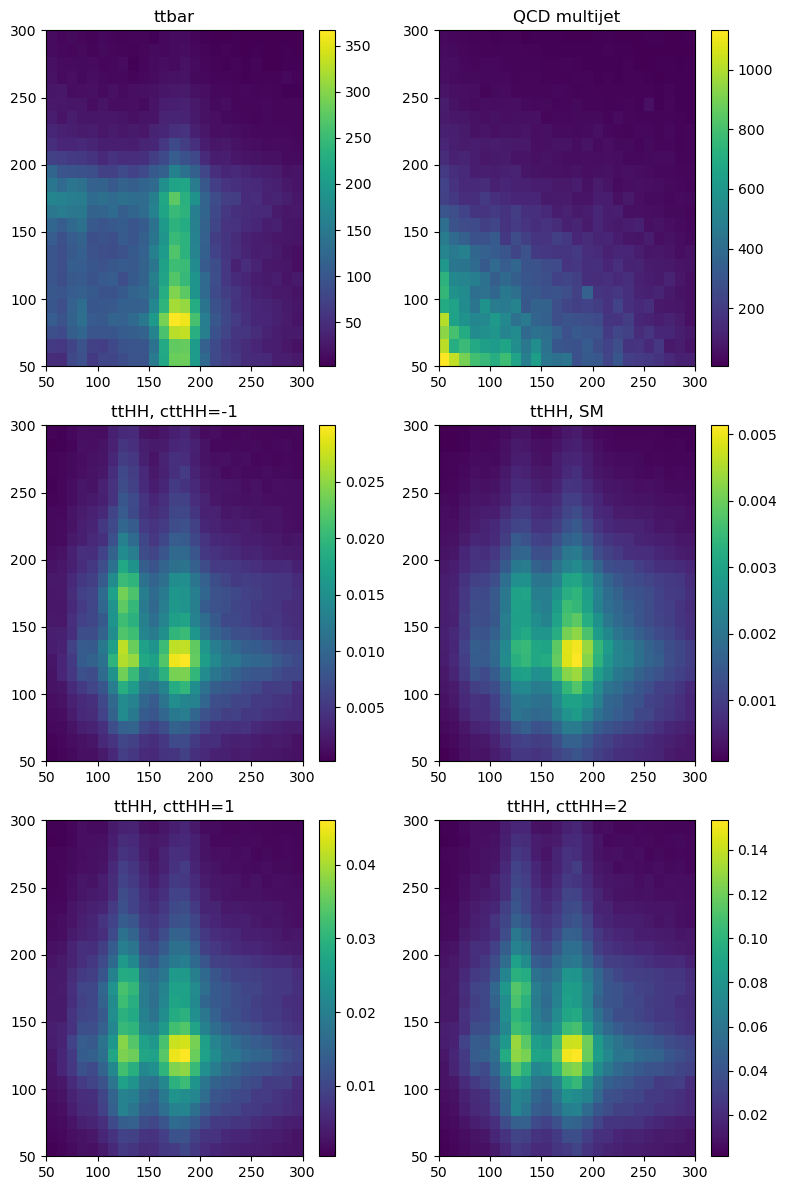

In [8]:
bins = np.linspace(50,300,26)

ncol = 2 
nrow = 3 
fig,ax2d = plt.subplots(nrow,ncol,figsize=(8,12))
irow = 0 
icol = 0 

GeV = 1000.

for samp in inputs.keys(): 
    if( 'ttHH' in samp ): continue

    print(f'Plotting: {samp}')

    msel = get_sel( indfs[samp] , xbbwp)
    
    counts, xedges, yedges, im = ax2d[irow,icol].hist2d( 
        indfs[samp][msel]['ttHH_LRJet1_m_NOSYS']/GeV , 
        indfs[samp][msel]['ttHH_LRJet2_m_NOSYS']/GeV , 
        bins=bins,
        weights=indfs[samp][msel]['mc_sf'], 
        label=samp,
        #vmax=5
    )

    ax2d[irow,icol].set_title(samp)
    fig.colorbar(im, ax=ax2d[irow,icol])
    
    icol+=1
    if( icol==ncol ): 
        irow+=1 
        icol=0


for eftw in [-1,0,1,2]:
    samp = 'ttHH'
    msel = get_sel( indfs[samp] , xbbwp)

    if( eftw != 0 ):
        samp = f'ttHH, cttHH={eftw}'
        wstr = getEFTweightstring(eftw)
        weights = indfs['ttHH'][msel][f'ttHH_eft_weight_heft_shape_CttHH_{wstr}_NOSYS'] * \
                           indfs['ttHH'][msel][f'ttHH_eft_weight_heft_norm_CttHH_{wstr}_NOSYS'] * \
                           indfs['ttHH'][msel][f'mc_sf']
    else: 
        samp = f'ttHH, SM'
        weights = indfs['ttHH'][msel][f'mc_sf'] 

    print(f'Plotting: {samp}')

    counts, xedges, yedges, im = ax2d[irow,icol].hist2d( 
        indfs['ttHH'][msel]['ttHH_LRJet1_m_NOSYS']/GeV , 
        indfs['ttHH'][msel]['ttHH_LRJet2_m_NOSYS']/GeV , 
        bins=bins,
        weights=weights,
        label=samp,
        #vmax=5
    )
    ax2d[irow,icol].set_title(samp)
    fig.colorbar(im, ax=ax2d[irow,icol])

    icol+=1
    if( icol==ncol ): 
        irow+=1 
        icol=0

plt.tight_layout()

Plotting: ttbar
Mode LRJet1_m: 177.5 GeV
Mode LRJet2_m: 82.5 GeV


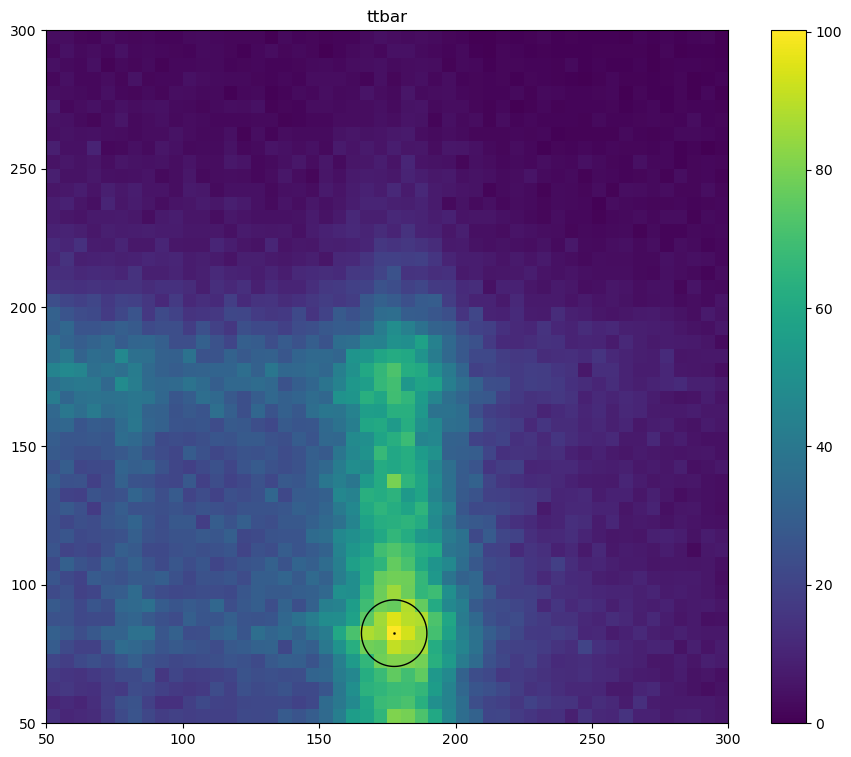

In [9]:
# print ttbar
# bins = np.linspace(50,300,70)
bins = np.linspace(50, 300, 51)   # 50 bins, 5 GeV each

fig, ax_ttbar = plt.subplots(figsize=(11,9))

GeV = 1000.
for samp in inputs.keys():
    if samp == 'ttbar':
        print(f'Plotting: {samp}')
        
        msel = get_sel( indfs[samp] , xbbwp)
        
        counts, xedges, yedges, im = ax_ttbar.hist2d( 
        indfs[samp][msel]['ttHH_LRJet1_m_NOSYS']/GeV , 
        indfs[samp][msel]['ttHH_LRJet2_m_NOSYS']/GeV , 
        bins=bins,
        weights=indfs[samp][msel]['mc_sf'], 
        #vmax=5
        )
        ax_ttbar.set_title(samp)
        fig.colorbar(im, ax=ax_ttbar)

        # find modes of axis
        counts_x = counts.sum(axis=1)  # LRJet1 mass distribution
        counts_y = counts.sum(axis=0)  # LRJet2 mass distribution
    else:
        continue

# calculate bin centers
centers = 0.5*(bins[1:] + bins[:-1]) 
# bins[1:] = right edges, every edge except first
# bins[:-1] = left edges, every edge except last

# mode = center of the bin with max weighted count
mode_x = centers[np.argmax(counts_x)]
mode_y = centers[np.argmax(counts_y)]
modes = (mode_x, mode_y)

print(f'Mode LRJet1_m: {mode_x:.1f} GeV')
print(f'Mode LRJet2_m: {mode_y:.1f} GeV')

# print centerpoint
ax_ttbar.scatter(
    mode_x, mode_y,
    marker='.', s=10, color='black',
    edgecolor='black', linewidth=0.2,
)

# print circle
circle = CirclePolygon((mode_x, mode_y), radius=12, resolution=100, 
                       facecolor='none', edgecolor='black')
ax_ttbar.add_patch(circle)

fig.savefig('Sep30-2026_2Dmass_ttbar.jpg')

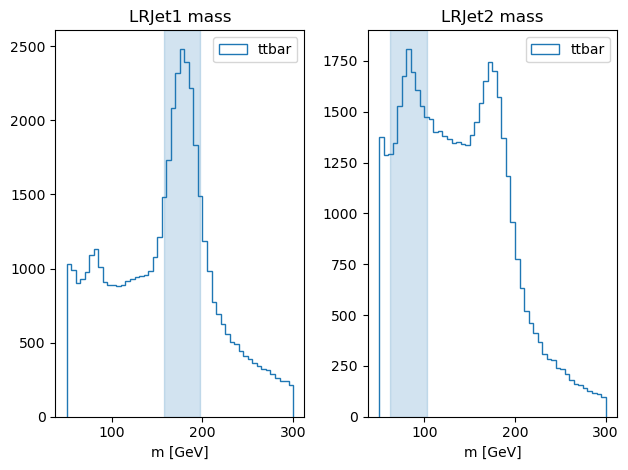

In [10]:
# plot 1d mass histograms for ttbar - updated to make more general

fig, axes = plt.subplots(1, 2)

# (axis, column, title) for each histogram
panels = [
    (axes[0], 'ttHH_LRJet1_m_NOSYS', 'LRJet1 mass'),
    (axes[1], 'ttHH_LRJet2_m_NOSYS', 'LRJet2 mass'),
]

counts = []

for samp in inputs.keys():
    if samp != 'ttbar':
        continue
    msel = get_sel(indfs[samp], xbbwp)
    for ax, col, title in panels:
        c = ax.hist(indfs[samp][msel][col] / GeV, 
                bins=bins,
                weights=indfs[samp][msel]['mc_sf'],
                histtype='step', 
                label=samp)
        counts.append(c)
        ax.set_title(title)
        ax.set_xlabel('m [GeV]')

for ax in axes:
    ax.legend()  # call once after all samples are drawn

counts_x, counts_y = counts
ax_x, ax_y = axes

# graph yield range
r = 20.0
for i in range(0,2):
    lo, hi = modes[i] - r, modes[i] + r
    axes[i].axvspan(lo, hi, color='tab:blue', alpha=0.2, zorder=0)

plt.tight_layout()

fig.savefig('Sep21-2026_1Dmass_ttbar.jpg')

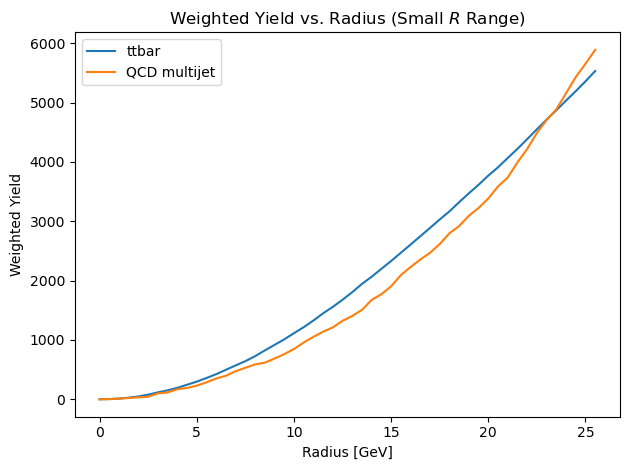

In [11]:
'''
# define a function for checking if a point is within bounds of a circle with radius r
def yield_check(r, x, y, h=mode_x, k=mode_y):
    """
    Checks if a point (x, y) is inside or on the boundary of a circle 
    with radius r centered at (h, k). Default center is modes (mode_x, mode_y).
    """
    return r**2 >= (x - h)**2 + (y - k)**2

radius = np.arange(0,251,1)

msel = get_sel(indfs['ttbar'], xbbwp)
x_ttbar = indfs['ttbar'][msel]['ttHH_LRJet1_m_NOSYS']/GeV
y_ttbar = indfs['ttbar'][msel]['ttHH_LRJet2_m_NOSYS']/GeV
d_ttbar = (x_ttbar - mode_x)**2 + (y_ttbar - mode_y)**2

weight_ttbar = indfs[samp][msel]['mc_sf']

yields_ttbar = np.array([weight_ttbar[d_ttbar < r**2].sum() for r in radius])

# do the same for QCD multijet
msel = get_sel(indfs['QCD multijet'], xbbwp)
x_QCD = indfs['QCD multijet'][msel]['ttHH_LRJet1_m_NOSYS']/GeV
y_QCD = indfs['QCD multijet'][msel]['ttHH_LRJet2_m_NOSYS']/GeV
d_QCD = (x_QCD - mode_x)**2 + (y_QCD - mode_y)**2

weight_QCD = indfs['QCD multijet'][msel]['mc_sf']

yields_QCD = np.array([weight_QCD[d_QCD < r**2].sum() for r in radius])

fig, ax = plt.subplots(1, 1)

plt.plot(radius, yields_ttbar, label = 'ttbar')
plt.plot(radius, yields_QCD, label = 'QCD')

plt.title('Weighted Yield vs. Radius')
plt.xlabel('Radius [GeV]')
plt.ylabel('Weighted Yield')
ax.set_ylim(0, 80000)

plt.legend()
'''
# small r range (close-up of QCD overtaking ttbar)
# df = dataframe
def yield_vs_radius(df, sel, radii):
    """
    Weighted yield inside a circle of each radius, centered at
    (mode_x, mode_y) in the (LRJet1 mass, LRJet2 mass) plane.
    Boundary is included (<=).
    """
    x = df[sel]['ttHH_LRJet1_m_NOSYS'] / GeV
    y = df[sel]['ttHH_LRJet2_m_NOSYS'] / GeV
    w = df[sel]['mc_sf']
    d2 = (x - mode_x)**2 + (y - mode_y)**2
    return np.array([w[d2 <= r**2].sum() for r in radii])

radius = np.arange(0, 26, 0.5)

fig, ax = plt.subplots()
for samp in ['ttbar', 'QCD multijet']:
    sel = get_sel(indfs[samp], xbbwp)
    ax.plot(radius, yield_vs_radius(indfs[samp], sel, radius), label=samp)

ax.set_title('Weighted Yield vs. Radius (Small $R$ Range)')
ax.set_xlabel('Radius [GeV]')
ax.set_ylabel('Weighted Yield')
ax.legend()

plt.tight_layout()
fig.savefig('Oct03-2026_yield_vs_smallr.jpg')

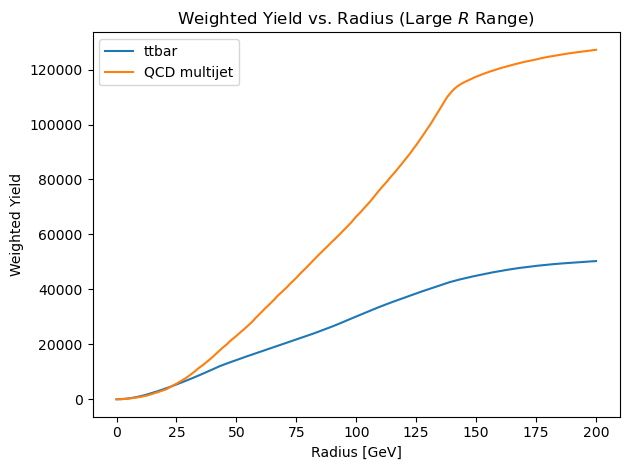

In [12]:
# large r range (see dropoff)
radius = np.arange(0, 201, 1)

fig, ax = plt.subplots()
for samp in ['ttbar', 'QCD multijet']:
    sel = get_sel(indfs[samp], xbbwp)
    ax.plot(radius, yield_vs_radius(indfs[samp], sel, radius), label=samp)

ax.set_title('Weighted Yield vs. Radius (Large $R$ Range)')
ax.set_xlabel('Radius [GeV]')
ax.set_ylabel('Weighted Yield')
ax.legend()

plt.tight_layout()
fig.savefig('Oct03-2026_yield_vs_larger.jpg')

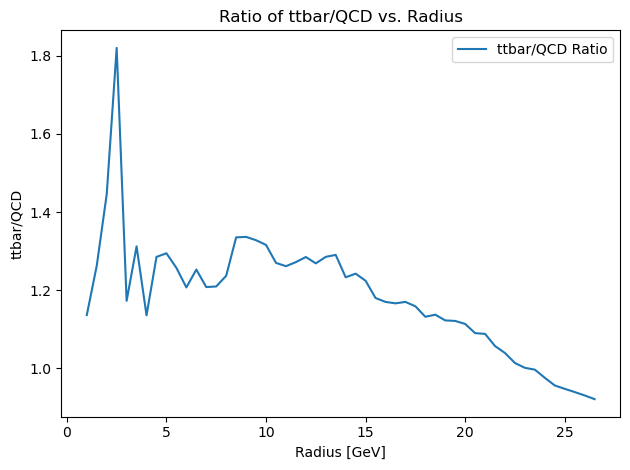

In [13]:
# ratio of ttbar / QCD as radius increases
# don't include r = 0 to avoid divide by zero error
radius = np.arange(1, 27, 0.5)

yields = []

for samp in ['ttbar', 'QCD multijet']:
    sel = get_sel(indfs[samp], xbbwp)
    yields.append(yield_vs_radius(indfs[samp], sel, radius))
    # yields[0] = ttbar, yields[1] = QCD

ratio = yields[0] / yields[1]

fig, ax = plt.subplots()
ax.plot(radius, ratio, label = 'ttbar/QCD Ratio')

ax.set_title('Ratio of ttbar/QCD vs. Radius')
ax.set_xlabel('Radius [GeV]')
ax.set_ylabel('ttbar/QCD')
ax.legend()

plt.tight_layout()
fig.savefig('Oct03-2026_ratio1.jpg')

[1.13636021 1.35620039 1.67860004 1.26735451 1.22017851 1.26273318
 1.33175831 1.48769797 1.58305827 1.39727464 1.44536977 1.55708799
 1.58717747 1.6445148  1.76413129 1.82009016 0.99675271 1.03167361
 1.09241108 1.14188242 1.17279674 1.21604843 1.2419545  1.30121303
 1.30250637 1.31222792 1.28981717 1.09273028 1.07162539 1.10481908
 1.1356888  1.15872463 1.21061662 1.22134966 1.24200263 1.28524653
 1.30005946 1.30460478 1.29045052 1.32579076 1.2944765  1.33152841
 1.25427917 1.20736559 1.22751191 1.25714734 1.22998929 1.24095961
 1.20237618 1.18094393 1.20708607 1.21262594 1.23263859 1.24651524
 1.26166251 1.25276974 1.19695306 1.18815028 1.19337267 1.18835292
 1.20805654 1.22679346 1.22174414 1.22827059 1.23511171 1.20957027
 1.20631649 1.20332951 1.22127661 1.22367767]


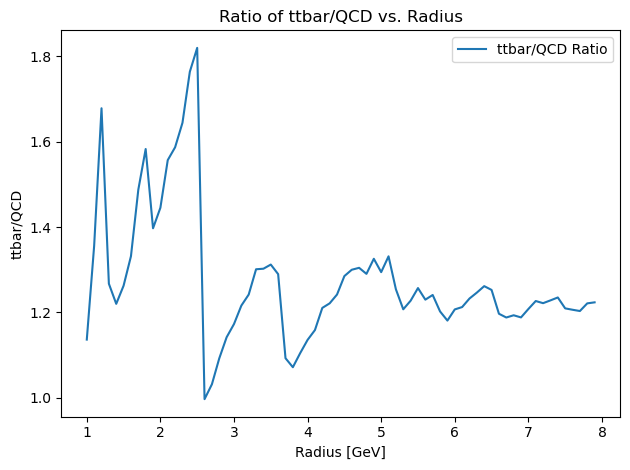

In [14]:
# ratio of ttbar / QCD as radius increases
# don't include r = 0 to avoid divide by zero error
radius = np.arange(1, 8, 0.1)

yields = []

for samp in ['ttbar', 'QCD multijet']:
    sel = get_sel(indfs[samp], xbbwp)
    yields.append(yield_vs_radius(indfs[samp], sel, radius))
    # yields[0] = ttbar, yields[1] = QCD

ratio = yields[0] / yields[1]
print(ratio)

fig, ax = plt.subplots()
ax.plot(radius, ratio, label = 'ttbar/QCD Ratio')

ax.set_title('Ratio of ttbar/QCD vs. Radius')
ax.set_xlabel('Radius [GeV]')
ax.set_ylabel('ttbar/QCD')
ax.legend()

plt.tight_layout()
fig.savefig('Oct03-2026_ratio2.jpg')

[ 1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5  7.   7.5
  8.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5 14.  14.5
 15.  15.5 16.  16.5 17.  17.5 18.  18.5 19.  19.5 20.  20.5 21.  21.5
 22.  22.5 23.  23.5 24.  24.5 25.  25.5 26.  26.5]
[0.53191414 0.5580566  0.59106389 0.64540141 0.53976367 0.56751668
 0.53176699 0.56241045 0.56417074 0.55696291 0.54691391 0.55610199
 0.54711305 0.54742331 0.55297419 0.57177313 0.57199554 0.5704362
 0.56820113 0.55946135 0.55780816 0.5598404  0.56236207 0.55921334
 0.56242925 0.56339147 0.5521809  0.5540338  0.55039527 0.54129417
 0.53918555 0.53840265 0.53917765 0.53678535 0.53096676 0.53212703
 0.52889973 0.52860657 0.52689492 0.52155563 0.52111689 0.51387124
 0.50962307 0.50339581 0.50034237 0.4991658  0.49387419 0.48880957
 0.48655177 0.48436895 0.48205462 0.4794889 ]


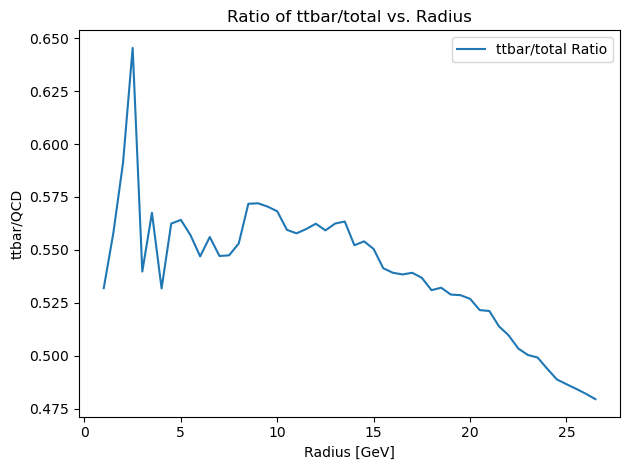

In [15]:
# ratio of ttbar / ttbar + QCD vs. radius
radius = np.arange(1, 27, 0.5)
print(radius)

yields = []

for samp in ['ttbar', 'QCD multijet']:
    sel = get_sel(indfs[samp], xbbwp)
    yields.append(yield_vs_radius(indfs[samp], sel, radius))
    # yields[0] = ttbar, yields[1] = QCD

ratio = yields[0] / (yields[0] + yields[1])
print(ratio)

fig, ax = plt.subplots()
ax.plot(radius, ratio, label = 'ttbar/total Ratio')

ax.set_title('Ratio of ttbar/total vs. Radius')
ax.set_xlabel('Radius [GeV]')
ax.set_ylabel('ttbar/QCD')
ax.legend()

plt.tight_layout()
fig.savefig('Oct11-2026_ttbartotal.jpg')

[ 1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5  7.   7.5
  8.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5 14.  14.5
 15.  15.5 16.  16.5 17.  17.5 18.  18.5 19.  19.5]
[0.53191414 0.5580566  0.59106389 0.64540141 0.53976367 0.56751668
 0.53176699 0.56241045 0.56417074 0.55696291 0.54691391 0.55610199
 0.54711305 0.54742331 0.55297419 0.57177313 0.57199554 0.5704362
 0.56820113 0.55946135 0.55780816 0.5598404  0.56236207 0.55921334
 0.56242925 0.56339147 0.5521809  0.5540338  0.55039527 0.54129417
 0.53918555 0.53840265 0.53917765 0.53678535 0.53096676 0.53212703
 0.52889973 0.52860657]


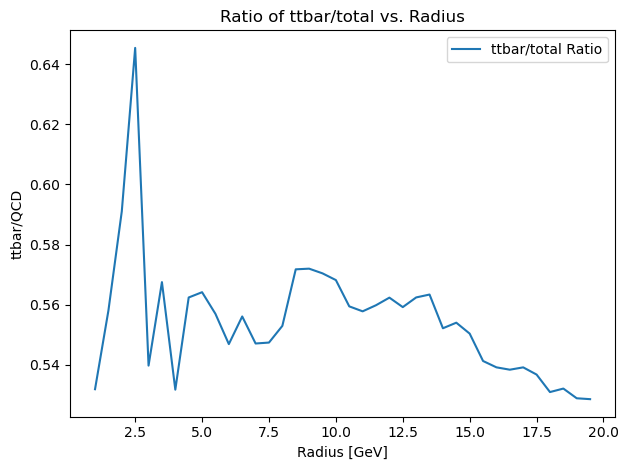

In [16]:
# ratio of ttbar / ttbar + QCD vs. radius
radius = np.arange(1, 20, 0.5)
print(radius)

yields = []

for samp in ['ttbar', 'QCD multijet']:
    sel = get_sel(indfs[samp], xbbwp)
    yields.append(yield_vs_radius(indfs[samp], sel, radius))
    # yields[0] = ttbar, yields[1] = QCD

ratio = yields[0] / (yields[0] + yields[1])
print(ratio)

fig, ax = plt.subplots()
ax.plot(radius, ratio, label = 'ttbar/total Ratio')

ax.set_title('Ratio of ttbar/total vs. Radius')
ax.set_xlabel('Radius [GeV]')
ax.set_ylabel('ttbar/QCD')
ax.legend()

plt.tight_layout()
fig.savefig('Oct11-2026_ttbartotal_small.jpg')

In [17]:
# CHOSEN RADIUS: r = 10 GeV
r = np.array([10])

In [18]:
# yield of ttHH (should be small)
# visualize using pie chart - relative fractions of ttbar, QCD out of total

xbbwp = 'inc' # inclusive

# more flexible get_sel, added topwp
def get_sel(df, xbbwp, topwp=4): 

    nlrjsel = df['nLargeRJets']>=3
    DTop_cut = topwp
    
    # cols = [f'ttHH_LRJet{i}_GN3XPV01_passTop_NOSYS' for i in range(1,6)]
    # valid_scores = df[cols].where(df[cols] != -99)
    # topsel = ((valid_scores > 0).sum(axis=1) >= 1)

    # ttHH_LRJet1_GN3XPV01_passHbb_FlatMassQCDEff_0p25_NOSYS
    if xbbwp == 'inc':
        hsel = np.ones_like(nlrjsel)
    else:
        cols = [f'ttHH_LRJet{i}_GN3XPV01_passHbb_FlatMassQCDEff_{xbbwp}_NOSYS' for i in range(1,6)]
        valid_scores = df[cols].where(df[cols] != -99)
        hsel = ((valid_scores > 0).sum(axis=1) >= 2)
    
    if topwp == 'inc':
        topsel = np.ones_like(nlrjsel)
    else:
        cols = [f'ttHH_LRJet{i}_GN3XPV01_DTop_NOSYS' for i in range(1,5)]
        valid_scores = df[cols].where(df[cols] != -99)
        topsel = ((valid_scores > DTop_cut).sum(axis=1) >= 1)
    # masscut = ( 
    #     ((df['ttHH_LRJet1_mass_NOSYS']>100)&(df['ttHH_LRJet1_mass_NOSYS']<200))
    #     &((df['ttHH_LRJet2_mass_NOSYS']>100)&(df['ttHH_LRJet2_mass_NOSYS']<200)))

    masscut = ( ( df['ttHH_LRJet2_m_NOSYS']/GeV + df['ttHH_LRJet1_m_NOSYS']/GeV ) > 150. )
    
    msel = hsel&topsel&nlrjsel
    return msel

In [19]:
yields = []

for samp in ['ttbar', 'QCD multijet', 'ttHH']:
    sel = get_sel(indfs[samp], xbbwp, topwp=4)
    yields.append(yield_vs_radius(indfs[samp], sel, r))
    # yields[0] = ttbar, yields[1] = QCD, yields[2] = ttHH
print(yields)

[array([1113.82883812]), array([846.4432943]), array([0.00813036])]


In [21]:
total = np.sum(yields)
ttbar_slice = yields[0][0]/total
QCD_slice = yields[1][0]/total
ttHH_slice = yields[2][0]/total

pie_yields = np.array([ttbar_slice, QCD_slice, ttHH_slice])
print(pie_yields)
print(ttbar_slice + QCD_slice + ttHH_slice)

[5.68198772e-01 4.31797080e-01 4.14754909e-06]
1.0


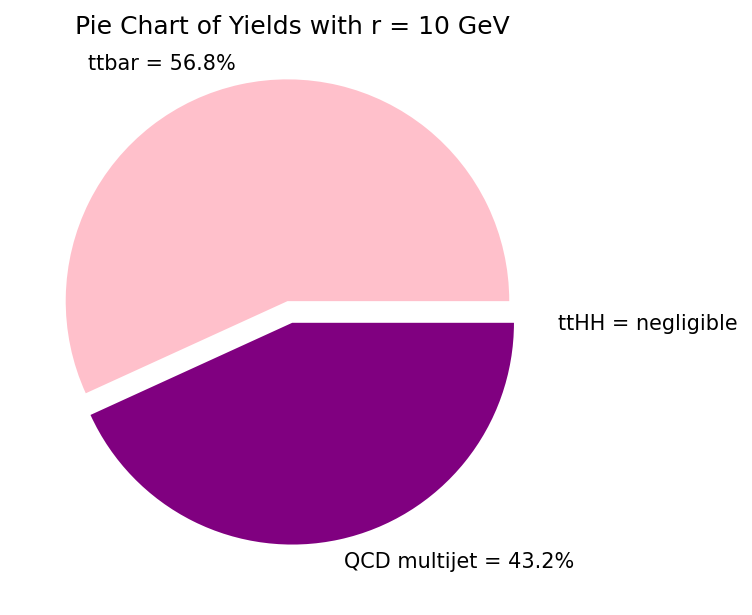

In [22]:
fig, ax = plt.subplots(dpi=150)

labels = ['ttbar = 56.8%', 'QCD multijet = 43.2%', 'ttHH = negligible']
explode = (0.1, 0, 0.1)
colors = ['pink', 'purple', 'green']

ax.pie(pie_yields, explode=explode, labels=labels, colors=colors)

ax.set_title("Pie Chart of Yields with r = 10 GeV")
fig.savefig('Oct20-2026_pie_yields.jpg')